# Model Comparison

Saved held-out results from the grouped-split analyses in [regression.ipynb](regression.ipynb), [transformer.ipynb](transformer.ipynb), [tpot.ipynb](tpot.ipynb), and [decision-tree-classifier.ipynb](decision-tree-classifier.ipynb). All use the same deterministic `GroupShuffleSplit` (random state 42) and 132-row test set. These tables summarize the notebooks' saved outputs; models are not retrained here.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

overview = pd.DataFrame([
    {
        "model": "Majority baseline",
        "variant": "always vilifying_opponents",
        "accuracy": 0.538,
        "macro_precision": 0.108,
        "macro_recall": 0.200,
        "macro_f1": 0.140,
        "weighted_f1": 0.376,
        "test_rows": 132,
        "source": "decision-tree-classifier.ipynb",
    },
    {
        "model": "TF-IDF logistic regression",
        "variant": "without stopword labels",
        "accuracy": 0.742,
        "macro_precision": 0.571,
        "macro_recall": 0.568,
        "macro_f1": 0.557,
        "weighted_f1": 0.708,
        "test_rows": 132,
        "source": "regression.ipynb",
    },
    {
        "model": "Sentence embeddings + logistic regression",
        "variant": "djovak/embedic-large",
        "accuracy": 0.826,
        "macro_precision": 0.628,
        "macro_recall": 0.728,
        "macro_f1": 0.666,
        "weighted_f1": 0.788,
        "test_rows": 132,
        "source": "transformer.ipynb",
    },
    {
        "model": "TF-IDF logistic regression",
        "variant": "with Serbian stopword labels",
        "accuracy": 0.682,
        "macro_precision": 0.551,
        "macro_recall": 0.527,
        "macro_f1": 0.490,
        "weighted_f1": 0.634,
        "test_rows": 132,
        "source": "regression.ipynb",
    },
    {
        "model": "Hierarchical logistic regression",
        "variant": "without stopword labels",
        "accuracy": 0.697,
        "macro_precision": 0.547,
        "macro_recall": 0.484,
        "macro_f1": 0.493,
        "weighted_f1": 0.655,
        "test_rows": 132,
        "source": "regression.ipynb",
    },
    {
        "model": "Hierarchical logistic regression",
        "variant": "with Serbian stopword labels",
        "accuracy": 0.682,
        "macro_precision": 0.572,
        "macro_recall": 0.521,
        "macro_f1": 0.504,
        "weighted_f1": 0.628,
        "test_rows": 132,
        "source": "regression.ipynb",
    },
    {
        "model": "Decision tree",
        "variant": "with Serbian stopword labels",
        "accuracy": 0.614,
        "macro_precision": 0.384,
        "macro_recall": 0.356,
        "macro_f1": 0.355,
        "weighted_f1": 0.567,
        "test_rows": 132,
        "source": "decision-tree-classifier.ipynb",
    },
    {
        "model": "TPOT search",
        "variant": "linear search space; 15-minute budget",
        "accuracy": 0.667,
        "macro_precision": 0.554,
        "macro_recall": 0.560,
        "macro_f1": 0.528,
        "weighted_f1": 0.655,
        "test_rows": 132,
        "source": "tpot.ipynb",
    },
])

display(
    overview.sort_values("macro_f1", ascending=False)
    .style.format({
        "accuracy": "{:.3f}",
        "macro_precision": "{:.3f}",
        "macro_recall": "{:.3f}",
        "macro_f1": "{:.3f}",
        "weighted_f1": "{:.3f}",
    })
)

,model,variant,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,test_rows,source
2,Sentence embeddings + logistic regression,djovak/embedic-large,0.826,0.628,0.728,0.666,0.788,132,transformer.ipynb
1,TF-IDF logistic regression,without stopword labels,0.742,0.571,0.568,0.557,0.708,132,regression.ipynb
7,TPOT search,linear search space; 15-minute budget,0.667,0.554,0.560,0.528,0.655,132,tpot.ipynb
5,Hierarchical logistic regression,with Serbian stopword labels,0.682,0.572,0.521,0.504,0.628,132,regression.ipynb
4,Hierarchical logistic regression,without stopword labels,0.697,0.547,0.484,0.493,0.655,132,regression.ipynb
3,TF-IDF logistic regression,with Serbian stopword labels,0.682,0.551,0.527,0.490,0.634,132,regression.ipynb
6,Decision tree,with Serbian stopword labels,0.614,0.384,0.356,0.355,0.567,132,decision-tree-classifier.ipynb
0,Majority baseline,always vilifying_opponents,0.538,0.108,0.200,0.140,0.376,132,decision-tree-classifier.ipynb


## Headline Metrics

Macro scores give each label equal weight; weighted F1 reflects the label distribution and is dominated by `vilifying_opponents`. Accuracy alone can hide missed minority classes. Rows are sorted by macro F1 in the table.

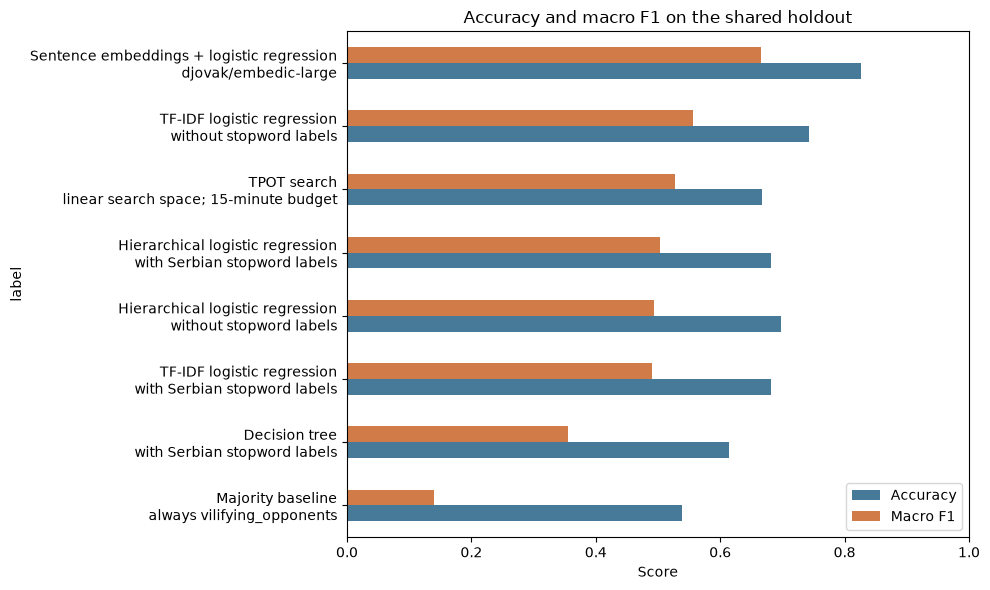

In [5]:
plot_data = overview.assign(
    label=overview["model"] + "\n" + overview["variant"]
).sort_values("macro_f1")
plot_data = plot_data.set_index("label")[["accuracy", "macro_f1"]]

axes = plot_data.plot.barh(figsize=(10, 6), color=["#477998", "#d17b49"])
axes.set_xlabel("Score")
axes.set_xlim(0, 1)
axes.set_title("Accuracy and macro F1 on the shared holdout")
axes.legend(["Accuracy", "Macro F1"], loc="lower right")
plt.tight_layout()
plt.show()

## Per-Label Results

The following table makes class-specific failures visible. Hierarchical logistic models are summarized above by their end-to-end metrics; this breakdown shows the direct logistic, sentence-embedding, tree, and TPOT classifiers.

In [6]:
class_metrics = pd.DataFrame([
    ("Majority baseline", "nothing", 0.000, 0.000, 0.000, 22),
    ("Majority baseline", "personality_cult", 0.000, 0.000, 0.000, 7),
    ("Majority baseline", "vilifying_eu", 0.000, 0.000, 0.000, 12),
    ("Majority baseline", "vilifying_neighbours", 0.000, 0.000, 0.000, 20),
    ("Majority baseline", "vilifying_opponents", 0.538, 1.000, 0.700, 71),
    ("TF-IDF logistic (no stopwords)", "nothing", 0.812, 0.591, 0.684, 22),
    ("TF-IDF logistic (no stopwords)", "personality_cult", 0.364, 0.571, 0.444, 7),
    ("TF-IDF logistic (no stopwords)", "vilifying_eu", 0.000, 0.000, 0.000, 12),
    ("TF-IDF logistic (no stopwords)", "vilifying_neighbours", 0.938, 0.750, 0.833, 20),
    ("TF-IDF logistic (no stopwords)", "vilifying_opponents", 0.742, 0.930, 0.825, 71),
    ("Sentence embeddings", "nothing", 0.909, 0.909, 0.909, 22),
    ("Sentence embeddings", "personality_cult", 0.583, 1.000, 0.737, 7),
    ("Sentence embeddings", "vilifying_eu", 0.000, 0.000, 0.000, 12),
    ("Sentence embeddings", "vilifying_neighbours", 0.800, 0.800, 0.800, 20),
    ("Sentence embeddings", "vilifying_opponents", 0.846, 0.930, 0.886, 71),
    ("Decision tree", "nothing", 0.346, 0.409, 0.375, 22),
    ("Decision tree", "personality_cult", 0.000, 0.000, 0.000, 7),
    ("Decision tree", "vilifying_eu", 0.000, 0.000, 0.000, 12),
    ("Decision tree", "vilifying_neighbours", 0.909, 0.500, 0.645, 20),
    ("Decision tree", "vilifying_opponents", 0.667, 0.873, 0.756, 71),
    ("TPOT search", "nothing", 0.800, 0.364, 0.500, 22),
    ("TPOT search", "personality_cult", 0.462, 0.857, 0.600, 7),
    ("TPOT search", "vilifying_eu", 0.000, 0.000, 0.000, 12),
    ("TPOT search", "vilifying_neighbours", 0.750, 0.750, 0.750, 20),
    ("TPOT search", "vilifying_opponents", 0.756, 0.831, 0.792, 71),
], columns=["model", "label", "precision", "recall", "f1", "support"])

label_order = [
    "nothing",
    "personality_cult",
    "vilifying_eu",
    "vilifying_neighbours",
    "vilifying_opponents",
]
class_metrics["label"] = pd.Categorical(
    class_metrics["label"], categories=label_order, ordered=True
)
display(
    class_metrics.sort_values(["label", "model"])
    .style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}"})
)

,model,label,precision,recall,f1,support
15,Decision tree,nothing,0.346,0.409,0.375,22
0,Majority baseline,nothing,0.000,0.000,0.000,22
10,Sentence embeddings,nothing,0.909,0.909,0.909,22
5,TF-IDF logistic (no stopwords),nothing,0.812,0.591,0.684,22
20,TPOT search,nothing,0.800,0.364,0.500,22
16,Decision tree,personality_cult,0.000,0.000,0.000,7
1,Majority baseline,personality_cult,0.000,0.000,0.000,7
11,Sentence embeddings,personality_cult,0.583,1.000,0.737,7
6,TF-IDF logistic (no stopwords),personality_cult,0.364,0.571,0.444,7
21,TPOT search,personality_cult,0.462,0.857,0.600,7


## Reading the Result

The best saved direct classifier here is sentence embeddings + logistic regression with `djovak/embedic-large` (0.826 accuracy, 0.666 macro F1), ahead of TF-IDF logistic regression without stopword labels (0.742 accuracy, 0.557 macro F1). TPOT reaches 0.667 accuracy and 0.528 macro F1, while the decision tree reaches 0.614 and 0.355. The embedding model still misses all 12 `vilifying_eu` examples; `personality_cult` has only 7 test examples, so its score is especially sensitive to a few headlines.

This is one grouped holdout, not a repeated-seed benchmark. Scores are rounded to three decimals and transcribed from the source notebooks' saved reports; rerun those notebooks and refresh these cells when the models or outputs change. The TPOT row reflects the saved 15-minute search run.